1. Load the dataset

In [1]:
import pandas as pd
df = pd.read_csv('heart_disease.csv')
df.head(5)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


2. Check the dataset

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [3]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


3. Separate X and y

In [4]:
x=df.drop('target',axis=1)
y=df['target']


4. Split into training and testing data

In [6]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(
    x,y,train_size=0.8,random_state=42,stratify=y
)

5. Create the AdaBoost model

In [7]:
from sklearn.ensemble import AdaBoostClassifier
model=AdaBoostClassifier(
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)   

8. Train the AdaBoost model

In [8]:
model.fit(x_train,y_train)


,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](100,)","[0.23,0.26,0.31,...,0.47,0.48,0.49]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[1.22,1.02,0.8 ,...,0.12,0.06,0.06]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](13,)","[0.07,0.05,0.06,...,0.02,0.08,0.05]"


9. Make predictions

In [12]:
y_train_pred=model.predict(x_train)
y_test_pred=model.predict(x_test)

10. Check training and Testing  accuracy

In [13]:
from sklearn.metrics import accuracy_score
train_accuracy=accuracy_score(y_train,y_train_pred)
print('Training accuracy',train_accuracy)
test_accuracy=accuracy_score(y_test,y_test_pred)
print('Testing accuracy',test_accuracy)


Training accuracy 0.9049586776859504
Testing accuracy 0.819672131147541


12. Classification report

In [14]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_test_pred))

              precision    recall  f1-score   support

           0       0.87      0.71      0.78        28
           1       0.79      0.91      0.85        33

    accuracy                           0.82        61
   macro avg       0.83      0.81      0.81        61
weighted avg       0.83      0.82      0.82        61



13. Confusion Matrix

In [18]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_test_pred)
print(cm)

[[20  8]
 [ 3 30]]


14. Draw Confusion Matrix

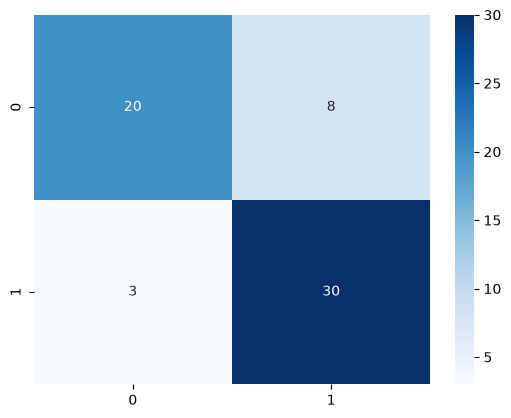

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap="Blues"
)
plt.xlabel=('Actual')
plt.ylabel=('Predcted')
plt.show()

15. Feature Importance

In [21]:
print(model.feature_importances_)

[0.06880907 0.04545245 0.05827345 0.12824406 0.20152744 0.
 0.01157549 0.14860482 0.0185861  0.16747074 0.02429431 0.07838241
 0.04877966]


16 draw feature importance

In [23]:
imp=pd.DataFrame({
    'Feature': x.columns,
    "Importance":model.feature_importances_
})
print(imp)

     Feature  Importance
0        age    0.068809
1        sex    0.045452
2         cp    0.058273
3   trestbps    0.128244
4       chol    0.201527
5        fbs    0.000000
6    restecg    0.011575
7    thalach    0.148605
8      exang    0.018586
9    oldpeak    0.167471
10     slope    0.024294
11        ca    0.078382
12      thal    0.048780


16. Visualize how the number of estimators affects accuracy

17 draw graph

16. Visualize how the number of estimators affects accuracy

In [26]:
from sklearn.metrics import accuracy_score
from sklearn.ensemble import AdaBoostClassifier

estimators = [10, 25, 50, 100, 150, 200]

train_accuracy = []
test_accuracy = []

for n in estimators:

    model_temp = AdaBoostClassifier(
        n_estimators=n,
        learning_rate=1.0,
        random_state=42
    )

    model_temp.fit(x_train, y_train)

    train_pred = model_temp.predict(x_train)
    test_pred = model_temp.predict(x_test)

    train_accuracy.append(
        accuracy_score(y_train, train_pred)
    )

    test_accuracy.append(
        accuracy_score(y_test, test_pred)
    )

TypeError: 'str' object is not callable

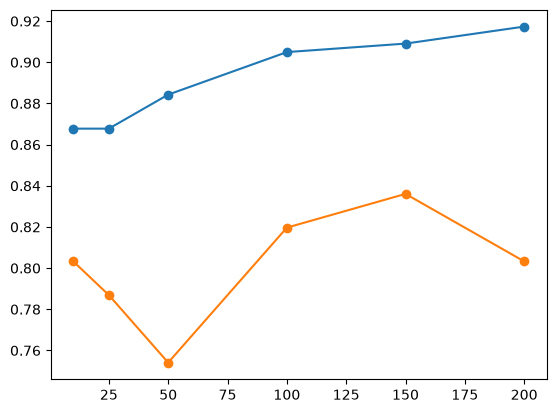

In [28]:
import matplotlib.pyplot as plt

plt.plot(
    estimators,
    train_accuracy,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    estimators,
    test_accuracy,
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Number of Estimators")
plt.ylabel("Accuracy")
plt.title("AdaBoost: Estimators vs Accuracy")

plt.legend()

plt.show()